In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
#load dataset

data = pd.read_csv("/content/drive/MyDrive/prediction_model/Salaryp.csv")

data.head()

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


In [10]:
data.describe()

,YearsExperience,Salary
count,35.000000,35.000000
mean,6.308571,83945.600000
std,3.618610,32162.673003
min,1.100000,37731.000000
25%,3.450000,57019.000000
50%,5.300000,81363.000000
75%,9.250000,113223.500000
max,13.500000,139465.000000


In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  35 non-null     float64
 1   Salary           35 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 692.0 bytes


In [6]:
data.corr()

,YearsExperience,Salary
YearsExperience,1.000000,0.982427
Salary,0.982427,1.000000


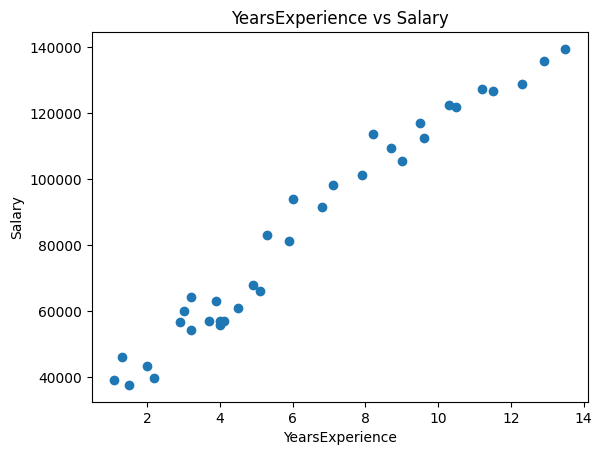

In [7]:
plt.scatter(data['YearsExperience'],data['Salary'])
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.title('YearsExperience vs Salary')
plt.show()

In [8]:
x = data[['YearsExperience']]       #input variables (Independent variable)
y = data['Salary']                  # output / prediction (dependent)

In [13]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=5)


In [14]:
#model training

from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_train)


LinearRegression()

In [15]:
y_pred = model.predict(x_test)

print("Predicted Salaries: ",y_pred)

Predicted Salaries:  [129181.73260181  97661.40635441  46003.0938934   80150.11399475
  88030.1955566   53883.17545525  38123.01233155]


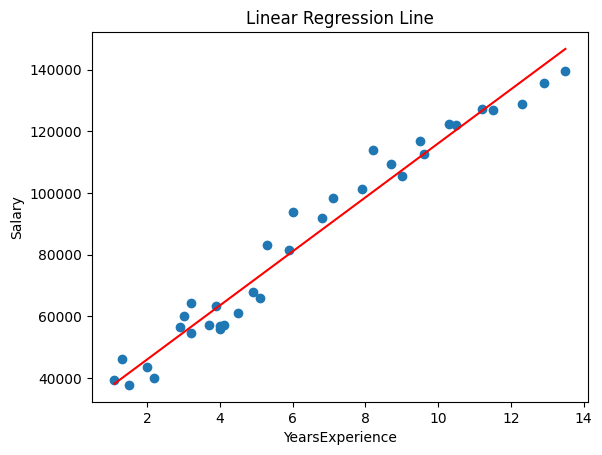

In [16]:
plt.scatter(x,y)
plt.plot(x,model.predict(x), color='red')
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.title('Linear Regression Line')
plt.show()

In [17]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print("Mean Square Error: ",mse)
print("R-Squared: ", r2)

Mean Square Error:  7085348.446346984
R-Squared:  0.9920709643930944


In [18]:
import joblib

joblib.dump(model,"/content/drive/MyDrive/prediction_model/salry_model_train.pkl")

print("your is saved")

your is saved


In [20]:
model_load = joblib.load("/content/drive/MyDrive/prediction_model/salry_model_train.pkl")

print("load hogya")



load hogya


In [23]:

year = float(input("Enter the Year of Experience: "))

year_input = [[year]]

predict_value = model_load.predict(year_input)

print(f'Your Predicted salary for Experience {year} is {predict_value[0]}')

Enter the Year of Experience: 6
Your Predicted salary for Experience 6.0 is 81025.67861273067


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
